# Multi-Task Contextual Decision-Making (Yang19 Cognitive Tasks)

This environment implements a suite of 20 context-dependent cognitive tasks inspired by the work of [Yang et al. (2019)](https://pubmed.ncbi.nlm.nih.gov/30643294/#:~:text=The%20brain%20has%20the%20ability,task%20representations%2C%20a%20critical%20feature). In these tasks, the agent must flexibly switch between different context rules on each trial, similar in spirit to the classic [context-dependent decision-making](https://neurogym.github.io/neurogym/latest/api/envs/#neurogym.envs.native.contextdecisionmaking.ContextDecisionMaking) experiment of [Mante et al. (2013)](https://www.nature.com/articles/nature12742). The key features of this multi-task environment are:

1. **Two-Choice Outputs** (`dim_ring=2`): All tasks share a common action space represented as positions on a ring. With `dim_ring = 2`, there are two choice outputs located at 0° and 180° on this ring (interpreted as "left" and "right" choices, respectively). The agent's goal on each trial is to select the correct one of these two outputs.
2. **Stimulus Inputs with Modality-Specific Evidence**: Each task provides sensory evidence (stimuli) that may come from one or two modalities. The stimuli are often encoded via a cosine-tuned input bump centered on one of the choice positions, with its amplitude representing the evidence strength. For example, a stimulus favoring the left choice might produce an activity peak at 0° on the input ring.
3. **Randomized Ground-Truth Choices**: The correct choice (ground truth) is randomized on each trial (for two choices: left or right). This means on some trials left is the correct answer, and on others right is correct, preventing the agent from biasing toward one action.
4. **Variable Difficulty Evidence**: The strength of the stimulus evidence (e.g., coherence level in a motion stimulus) is also randomly sampled each trial. Sometimes the evidence strongly favors one choice, and other times it is weak or ambiguous.

This collection of 20 tasks exercises various cognitive skills, including working memory (e.g., remembering stimuli across a delay in matching tasks), perceptual decision-making (integrating noisy sensory evidence over time), rule-based categorization, and inhibitory control (suppressing or initiating actions under certain rules). All tasks are implemented in a consistent format so that a single neural network agent can learn them together via supervised training.

In this notebook, we will:

1. Train an agent on the 20-task suite using supervised learning. We will generate trial data from the environment and train a recurrent neural network to predict the correct choices.
2. Evaluate the agent's performance and behavior across tasks. After training, we will examine how well the agent learned each of the 20 tasks and whether it can flexibly switch contexts from trial to trial.


# 0. Install Dependencies

To begin, install the `neurogym` package. This will automatically install all required dependencies, including Stable-Baselines3.

For detailed instructions on how to install `neurogym` within a conda environment or in editable mode, refer to the [installation instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation).


# 1. Training an Agent on Yang19 Cognitive Tasks


## 1.1 Environment Setup and Initial Agent Behavior

Let's begin by creating and exploring the environment using the `yang19` collection of tasks from NeuroGym. We’ll use the default configuration for all parameters except `dim_ring`, which we set to 2 in order to represent two alternative choices (left/right) arranged on a ring.

To get a sense of the environment dynamics, we’ll visualize a couple of representative tasks (`dm1` and `multidm`) to better understand their structure and how the agent is expected to interact with them.


### 1.1.1 Import Libraries


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

### 1.1.2 Environment Setup


In [2]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

We wrap the `yang19` environments using NeuroGym’s `ScheduleEnvs` wrapper, which allows us to interleave multiple tasks into a single training loop. Each cognitive task is instantiated as a separate environment, and a scheduling policy (`RandomSchedule`) determines which task is sampled on each trial. When `env_input=True`, a one-hot vector is appended to the observation to indicate the currently active task, allowing the agent to learn task-specific behavior within a unified architecture.


In [3]:
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# Make supervised dataset
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
# schedule = SequentialSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}

Observation space structure:
Box(-inf, inf, (25,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


### 1.1.3 Random Agent Behavior

Let's now plot the behavior of a random agent on the task. The agent will randomly choose between the two options (left/right, blue line), and we will visualize its behavior over 5 trials. We will also plot the reward received by the agent at each time step, as well as the performance on each trial. Note that performance is only defined at the end of a trial: it is 1 if the agent made the correct choice, and 0 otherwise.


In [4]:
obs, info = env.reset()

eval_monitor = Monitor(env)
print("\nEvaluating random policy performance...")
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")


Evaluating random policy performance...

Random policy metrics (100 trials):
Mean performance: 0.3900
Mean reward: 0.3900


# 2. Learning the Task as a Supervised Problem

We will now train the agent using supervised learning. NeuroGym provides functionality to generate a dataset directly from the environment, allowing us to sample batches of inputs and corresponding labels for training.


## 2.1 Converting the Environment to a Supervised Dataset


### 2.1.1 Dataset Setup


In [5]:
seq_len = 100
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
batch_size = 64
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

env = dataset.env

# Extract dimensions
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

# 20 observations for one-hot encoding of the 20 environments, 1 for fixation,
# 2 for each modality (2 modalities, 4 observations total), for a total of 25 observations
print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Get a batch of data
# inputs, target = dataset()
# print(f"Input batch shape: {inputs.shape}")
# print(f"Target batch shape: {target.shape}")
# print(inputs[90])

# Set device
device = 'cuda:0'
print(f"Using device: {device}")

Using sequence length: 100
Creating dataset with batch_size=64
Observation size: 25
Action size: 3
Using device: cuda:0


## 2.2 Training and Evaluating a Neural Network Model


### 2.2.1 Training the Model


In [6]:
# from pdm_model import Net, SimpleNet, DANN, ColEI
from net.colei import ColEI
from net.dann import DANN
from net.simple import SimpleNet
from net.eisep import EISepNet
from net.dbp import DBPN
from net.common import init_model

# This setting is low to speed up testing, we recommend setting it to at least 1000
def train(net, epochs=2000, lyapunov_every=100, lr=1e-3, wd=1e-5, batch_size=64):
    seq_len = 100
    dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

    net.train()
    # print('rec_filter:', net.lstm.rec_filter)
    # This weighting deprioritizes class 0 while keeping the other 16 classes equally important,
    # aligning with the reward distribution idea from the RL setting
    class_weights = torch.tensor([0.05] + [1.0]*(act_size - 1)).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    for name, param in net.named_parameters():
        print(name, param.shape)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # Training loop
    loss_history = []
    loss_log = np.zeros((epochs, 3))
    gradient_log = np.zeros((epochs, 1))
    spectral_radius_log = np.zeros((epochs, 1))
    rec_balance_log = np.zeros((epochs, seq_len))  # Track input balance
    n_lyapunov = epochs // lyapunov_every
    lyapunov_spectrum_log = np.zeros((n_lyapunov, net.hidden_size))  # Track Lyapunov spectrum
    ei_logit_log = np.zeros((n_lyapunov, net.hidden_size, 2))
    np.set_printoptions(threshold=np.inf)

    for i in range(epochs):
        # Get a batch of data
        inputs, targets = dataset()
        # print(inputs.shape, targets.shape)
        # print(inputs[..., -20:].argmax(axis=-1))
        # Convert to PyTorch tensors
        inputs = torch.from_numpy(inputs).float().to(device)
        targets = torch.from_numpy(targets).long().to(device)

        # Initialize hidden state
        # hidden = sl_model.init_hidden(inputs.size(1), device)


        # Forward pass with hidden state tracking
        outputs, eimask_logit, hidden = net(inputs)

        # Reshape for CrossEntropyLoss
        outputs_flat = outputs.reshape(-1, outputs.size(2))
        targets_flat = targets.reshape(-1)

        # Calculate loss
        # Weight the loss to account for class imbalance (very low weight to 0s, higher weights to 1s and 2s)
        decoding_loss = criterion(outputs_flat, targets_flat)


        if net.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            entropy_loss = net.get_ei_entropy_loss()
            loss_log[i, 2] = entropy_loss.item()
        else:
            entropy_loss = 0.0


        if isinstance(net, SimpleNet):
            l1_loss = net.lstm.Wrec_free.abs().mean()
        else:
            l1_loss = 0

        loss = 1 * entropy_loss + decoding_loss + l1_loss * 0

        # Backward pass and optimize
        loss.backward()
        # gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()
        if isinstance(net, DANN):
            gradient_log[i, 0] = net.danncell.Wex.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=None)
            net.zero_grad()
        elif isinstance(net, ColEI):
            gradient_log[i, 0] = net.colcell.W_pos.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=10)
            net.zero_grad()
        elif isinstance(net, DBPN):
            gradient_log[i, 0] = net.rnn.weight_hh_l0.grad.norm(2).item()
            net.update(optimizer)
            # net.zero_grad()
            optimizer.zero_grad()
        else:
            gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()
            optimizer.step()
            # Zero gradients
            optimizer.zero_grad()

        # Log spectral radius
        weight = net.get_actual_weight()
        try:
            spectral_radius = torch.linalg.eigvals(weight).abs().max().item()
        except:
            spectral_radius = torch.nan
            print('Eigenvalue computation did not converge')
        # print('spectral radius:', spectral_radius)
        spectral_radius_log[i, 0] = spectral_radius

        rec_balance_log[i] = hidden[-1].detach().cpu().numpy()

        # print statistics
        loss_history.append(loss.item())
        loss_log[i, 0] = loss.item()
        loss_log[i, 1] = decoding_loss.item()
        if i % lyapunov_every == 0:
            print('Epoch [{}/{}], Loss: {:.4f}'.format(i, epochs, loss.item()))
            # if net.entropy_loss:
            #     ei_logit_log[i // lyapunov_every] = eimask_logit.detach().cpu().numpy()
        #     # Calculate Lyapunov spectrum
            # lyapunov_spectrum, _ = net.compute_lyapunov_spectrum(inputs)
            # lyapunov_spectrum_log[i // lyapunov_every] = lyapunov_spectrum.detach().cpu().numpy()


    print('Finished Training')
    return net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyapunov_spectrum_log, ei_logit_log
    # Plot the loss curve
    # plt.figure(figsize=(8, 4))
    # plt.plot(loss_history)
    # plt.title('Training Loss')
    # plt.xlabel('Iterations')
    # plt.ylabel('Loss (50-iteration moving average)')
    # plt.grid(True, alpha=0.3)
    # plt.savefig('./output/multitask/yang19_loss_curve.png')
    # plt.show()

### 2.2.2 Evaluate the Model's Performance


In [7]:
from functools import partial
def test(net, sparsity_control=False):
    verbose = False
    # Evaluate performance of the trained model
    net.eval()
    # Initialize storage for each environment
    sl_mean_performance = {}
    for e_i in env.envs:
        sl_mean_performance[e_i.spec.id] = []

    # Evaluate for specified number of trials
    print(f"Evaluating model performance across {EVAL_TRIALS} trials...\n")
    
    if sparsity_control:
        device = 'cpu'
        actual_weight = net.get_actual_weight()
        sparsity_mask = torch.where(torch.abs(actual_weight)<0.1*torch.std(torch.abs(actual_weight)),0,1)
        # print(actual_weight.device, sparsity_mask.device)
        forward_function = partial(net.sc_forward, sparsity_mask=sparsity_mask)
    else:
        device = 'cuda:0'
        forward_function = net.forward
    for env_idx, e_i in enumerate(env.envs):
        data = {"action": [], "gt": [], "trial": []}
        total_correct = 0
        for trial_idx in range(EVAL_TRIALS):
            trial = e_i.new_trial()
            data["trial"].append(trial)
            ob, gt = e_i.ob, e_i.gt
            data["gt"].append(gt[-1])
            trial_length = ob.shape[0]

            # Add one-hot encoding for the environment
            env_one_hot = np.zeros((trial_length, len(env.envs)))
            env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

            # Concatenate original observation with one-hot encoding
            ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

            ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension

            inputs = torch.from_numpy(ob_with_env).float().to(device)
            # hidden = sl_model.init_hidden(1, device)

            with torch.no_grad():
                outputs, _, hidden = forward_function(inputs)
                pred_actions = torch.argmax(outputs, dim=2)
                data["action"].append(pred_actions[-1, 0].cpu().numpy())

            decision_idx = trial_length - 1
            is_correct = (gt[decision_idx] == pred_actions[decision_idx, 0].cpu().numpy())
            total_correct += is_correct

        accuracy = total_correct / EVAL_TRIALS
        sl_mean_performance[e_i.spec.id].append(accuracy)
        for key in data:
            if key != "trial":
                data[key] = np.array(data[key])


    # Print average performance
    print("Average performance across all environments:")
    mean_acc_all = np.array([np.mean(sl_mean_performance[e_i.spec.id]) for e_i in env.envs])
    for e_i in env.envs:
        mean_acc = np.mean(sl_mean_performance[e_i.spec.id])
        print(f"{e_i.spec.id}: {mean_acc:.4f}")
    return mean_acc_all





def plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax.plot(sorted_mean_ei[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C0')
        ax.plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[0].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        # ax[1].plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[1].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
    # ax[0].set_title('Lyapunov spectrum (EI)', fontsize=fontsize)
    # ax[1].set_title('Lyapunov spectrum (simple)', fontsize=fontsize)
    ax.set_xlabel('Lyapunov index', fontsize=fontsize)
    # ax[1].set_xlabel('Lyapunov index', fontsize=fontsize)
    ax.set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[1].set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[0].legend(fontsize=fontsize)
    # ax[1].legend(fontsize=fontsize)
    # for a in ax:
    #     a.tick_params(labelsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum.png')
    plt.show()

def plot_lyapunov_spectrum_separately(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple, lyapunov_every):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
    ax = ax.flatten()
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    # alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax[i].plot(sorted_mean_ei[i], label='EI', color='C0')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        ax[i].plot(sorted_mean_simple[i], label='simple', color='C1')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
        ax[i].set_title(f'Epoch {i+1}*{lyapunov_every}', fontsize=fontsize)
        if i > 14:
            ax[i].set_xlabel('Lyapunov index', fontsize=fontsize)
        if i % 5 == 0:
            ax[i].set_ylabel('Lyapunov exponent', fontsize=fontsize)
        ax[i].legend(fontsize=fontsize)
        ax[i].tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum_separately.png')
    plt.show()


In [12]:
import os, pickle
n_seed = 10
epochs = 3000
hidden_size = 64
def multiple_train_multilr(model_name, lrs):

    lyapunov_every = epochs//20
    hidden_size = 64
    n_lr = len(lrs)
    wd_ei = 0
    batch_size = 32
    test_EI_performance = np.zeros((n_lr, n_seed, len(env.envs)))
    loss_log_ei = np.zeros((n_lr, n_seed, epochs, 3))
    gradient_log_ei = np.zeros((n_lr, n_seed, epochs, 1))
    spectral_radius_log_ei = np.zeros((n_lr, n_seed, epochs, 1))
    rec_balance_log_ei = np.zeros((n_lr, n_seed, epochs, seq_len))
    lyapunov_spectrum_log_ei = np.zeros((n_lr, n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
    net_state_dicts = [[None]*n_seed for _ in range(n_lr)]

    for j, lr in enumerate(lrs):
        print(f"Learning rate {j+1}/{len(lrs)}: {lr}")
        for seed in range(n_seed):
            print(f"Seed {seed + 1}/{n_seed}")
            torch.manual_seed(seed)
            np.random.seed(seed)
            print('device:', device)
            net = init_model(ob_size, hidden_size, act_size, model_name).to(device)

            net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(net, epochs, lyapunov_every, lr=lr, wd=wd_ei,
                                                                                                            batch_size=batch_size)
            loss_log_ei[j, seed, :, :] = loss_log
            gradient_log_ei[j, seed, :, :] = gradient_log
            spectral_radius_log_ei[j, seed, :, :] = spectral_radius_log
            rec_balance_log_ei[j, seed, :, :] = rec_balance_log
            lyapunov_spectrum_log_ei[j, seed, :, :] = lyanpunov_spectrum_log

            test_EI_performance[j, seed, :] = test(net)
            net_state_dicts[j][seed] = net.state_dict()

    path = f'./result/multitask/{model_name}_performance.pkl'
    if not os.path.exists(os.path.dirname(path)):
        os.makedirs(os.path.dirname(path))
    info = {'performance': test_EI_performance,
            'loss_log_ei': loss_log_ei,
            'gradient_log_ei': gradient_log_ei,
            'spectral_radius_log_ei': spectral_radius_log_ei,
            'rec_balance_log_ei': rec_balance_log_ei,
            'lyapunov_spectrum_log_ei': lyapunov_spectrum_log_ei,
            'net_state_dicts': net_state_dicts}
    with open(path, 'wb') as f:
        pickle.dump(info, f)
    print(f"Saved performance to {path}")
    return net


def multiple_train(model_name):

    lyapunov_every = epochs//20
    hidden_size = 64
    if 'small' in model_name:
        hidden_size = 12
    wd_ei = 0
    batch_size = 32
    lr = 1e-2
    test_EI_performance = np.zeros((n_seed, len(env.envs)))
    loss_log_ei = np.zeros((n_seed, epochs, 3))
    gradient_log_ei = np.zeros((n_seed, epochs, 1))
    spectral_radius_log_ei = np.zeros((n_seed, epochs, 1))
    rec_balance_log_ei = np.zeros((n_seed, epochs, seq_len))
    lyapunov_spectrum_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
    net_state_dicts = [None]*n_seed
    ei_logit_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size, 2))

    for seed in range(n_seed):
        print(f"Seed {seed + 1}/{n_seed}")
        torch.manual_seed(seed+100)
        np.random.seed(seed+100)
        print('device:', device)
        net = init_model(ob_size, hidden_size, act_size, model_name).to(device)
        net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log, ei_logit_log = \
             train(net, epochs, lyapunov_every, lr=lr, wd=wd_ei, batch_size=batch_size)
        loss_log_ei[seed, :, :] = loss_log
        gradient_log_ei[seed, :, :] = gradient_log
        spectral_radius_log_ei[seed, :, :] = spectral_radius_log
        rec_balance_log_ei[seed, :, :] = rec_balance_log
        lyapunov_spectrum_log_ei[seed, :, :] = lyanpunov_spectrum_log
        ei_logit_log_ei[seed, :, :] = ei_logit_log

        test_EI_performance[seed, :] = test(net)
        net_state_dicts[seed] = net.state_dict()

    ###FIXME: note we are running the absolute model
    path = f'./result/multitask/lr1e-2_{model_name}_performance.pkl'
    if not os.path.exists(os.path.dirname(path)):
        os.makedirs(os.path.dirname(path))
    info = {'performance': test_EI_performance,
            'loss_log_ei': loss_log_ei,
            'gradient_log_ei': gradient_log_ei,
            'spectral_radius_log_ei': spectral_radius_log_ei,
            'rec_balance_log_ei': rec_balance_log_ei,
            'lyapunov_spectrum_log_ei': lyapunov_spectrum_log_ei,
            'net_state_dicts': net_state_dicts,
            'ei_logit_log_ei': ei_logit_log_ei}
    with open(path, 'wb') as f:
        pickle.dump(info, f)
    print(f"Saved performance to {path}")
    return net

In [9]:

# model_names = ['dbpn', 'dann_sgd', 'colei_sgd', 'dann_adam', 'colei_adam', 'simple', 'eisep']
# model_names = ['small_fixed_eisep', 'small_eisep']
# model_names = ['eisep_init_DBPN']
model_names = ['eisep']
# model_names = ['dann_adam', 'colei_adam']
# lrs = [1e-3]
# lrs = [1e-1, 5e-2, 1e-2, 5e-3, 1e-3, 5e-4, 1e-4]
for model_name in model_names:
    print(model_name)
    multiple_train(model_name)
raise ValueError('stop here')

eisep
Seed 1/10
device: cuda:0
init, model_name: eisep
EISep Net
Using UnFixed EISep RNN
lstm.Wrec_free torch.Size([64, 64])
lstm.bias torch.Size([64])
lstm.eimask_logit torch.Size([64, 2])
lstm.input_layer.weight torch.Size([64, 25])
lstm.input_layer.bias torch.Size([64])
lstm.output_layer.weight torch.Size([3, 64])
lstm.output_layer.bias torch.Size([3])


KeyboardInterrupt: 

In [13]:
from tkinter import font


def plot_test_performance_all(test_acc, env_names, model_names, colors, legend_names, show_values=True, title=''):
    # test_acc: [n_models, n_seed, n_envs]
    assert test_acc.shape == (len(model_names), n_seed, len(env_names))
    test_acc = np.where(test_acc is None, 0., test_acc)
    mean_acc = np.mean(test_acc, axis=1)
    std_acc = np.std(test_acc, axis=1)/np.sqrt(test_acc.shape[1])

    n_env = mean_acc.shape[1]
    x = np.arange(n_env)
    width = 0.8  # bar width

    fig, ax = plt.subplots(figsize=(20,4), constrained_layout=True)

    for i in range(mean_acc.shape[0]):
        bars = ax.bar(x + (i - mean_acc.shape[0]/2)*width/mean_acc.shape[0], mean_acc[i], width/mean_acc.shape[0],
                      yerr=std_acc[i], capsize=4, color=colors[i],
                      label=legend_names[i])
        # if show_values:
        #     ax.bar_label(bars, fmt='%.2f', padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(env_names, rotation=30, ha='right', fontsize=15)
    ax.set_ylabel('Test accuracy', fontsize=15)
    if title == '':
        ax.set_title(f'Performance on the cognitive task suite', fontsize=25)
    else:
        ax.set_title(f'{title} performance on the cognitive task suite', fontsize=25)
    ax.set_xmargin(0.01)
    ax.legend(fontsize=10, loc='lower left')
    ax.tick_params(labelsize=15)
    # plt.tight_layout()
    figname = f'./output/multitask/yang19_test_performance_{title}.png'
    plt.savefig(figname, dpi=600)
    print(figname)
    plt.show()
    plt.close()

    if title == '':
        fig, ax = plt.subplots(figsize=(6,3), constrained_layout=True)
    elif title == 'Weights-masked':
        fig, ax = plt.subplots(figsize=(6.5,3), constrained_layout=False)
        fig.subplots_adjust(left=0.11, right=0.96, bottom=0.3, top=0.9)

    elif title == 'Difference of':
        fig, ax = plt.subplots(figsize=(7,3), constrained_layout=False)
        fig.subplots_adjust(left=0.16, right=0.96, bottom=0.3, top=0.9)
    mean_all = mean_acc.mean(axis=1)
    std_all = std_acc.mean(axis=1)
    for i in range(len(model_names)):
        bars = ax.bar(i, mean_all[i], yerr=std_all[i], capsize=4, color=colors[i])
        if show_values:
            ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)
    ax.set_xticks(np.arange(len(model_names)))
    ax.set_xticklabels(legend_names[:len(model_names)], rotation=30, ha='right', fontsize=12)
    # ax.set_xticklabels(legend_names[:len(model_names)], fontsize=12)
    ax.set_ylabel('Test accuracy', fontsize=15)
    ax.tick_params(labelsize=15)
    if title != 'Difference of':
        ax.set_ylim(0,1.2)
    else:
        ax.set_ylim(-0.06,0.06)
    if title == '':
        ax.set_title(f'Performance averaged across tasks', fontsize=16)
    else:
        ax.set_title(f'{title} performance averaged across tasks', fontsize=16)
    # plt.tight_layout()
    figname = f'./output/multitask/yang19_test_performance_overall_{title}.png'
    plt.savefig(figname, dpi=400)
    print(figname)
    plt.show()
    plt.close()

def performance_vs_lr(test_acc, env_names, model_names, colors, legend_names, lrs, show_values=True, title=''):
    # test_acc: [n_models, n_lr, n_seed, n_envs]
    assert test_acc.shape == (len(model_names), len(lrs), n_seed, len(env_names))
    test_acc_flatten = test_acc.reshape(len(model_names), len(lrs), -1)
    mean_acc = np.mean(test_acc_flatten, axis=-1)
    std_acc = np.std(test_acc_flatten, axis=-1)/np.sqrt(test_acc_flatten.shape[-1])
    n_lr = len(lrs)
    fig, ax = plt.subplots(figsize=(10,5))
    for i in range(len(model_names)):
        ax.plot(lrs, mean_acc[i], marker='o', color=colors[i], label=legend_names[i])
        ax.fill_between(lrs, mean_acc[i]-std_acc[i], mean_acc[i]+std_acc[i], alpha=0.2, color=colors[i])
    ax.set_xscale('log')
    ax.set_xlabel('Learning rate')
    ax.set_ylabel('Test accuracy')
    ax.set_title('Performance vs Learning rate. '+title)
    ax.legend()
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_performance_vs_lr.png')
    plt.show()
    plt.close()
    return


0
1
2
3
4
5
6
./output/multitask/yang19_test_performance_.png


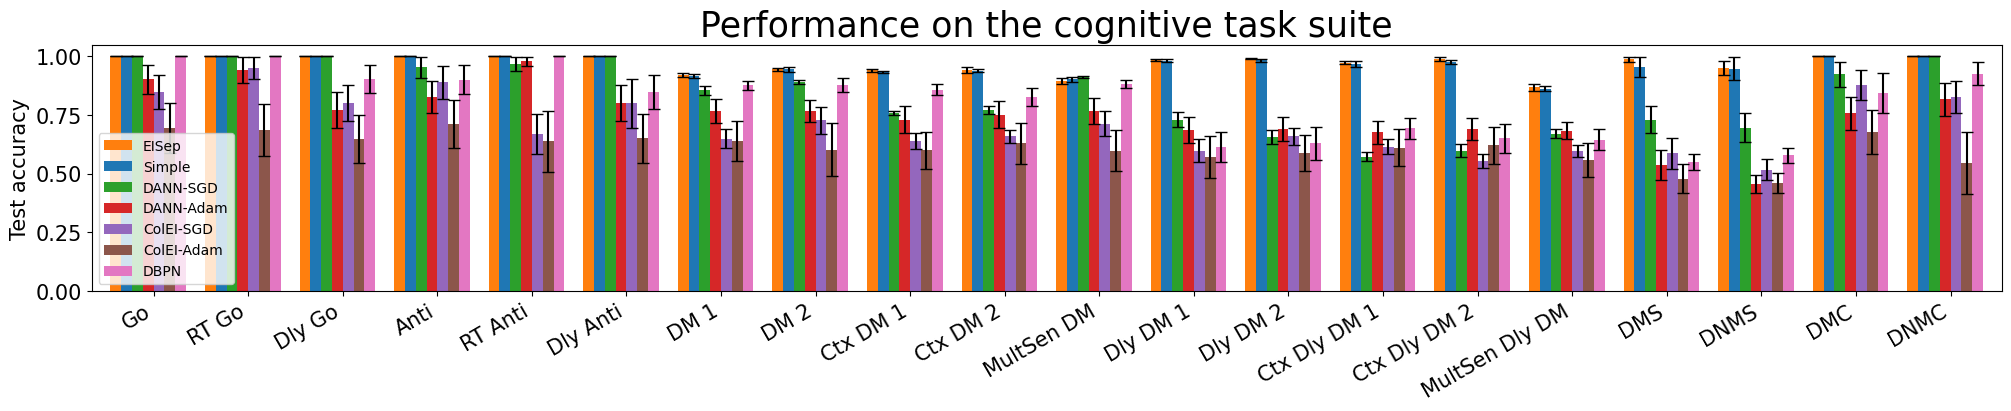

./output/multitask/yang19_test_performance_overall_.png


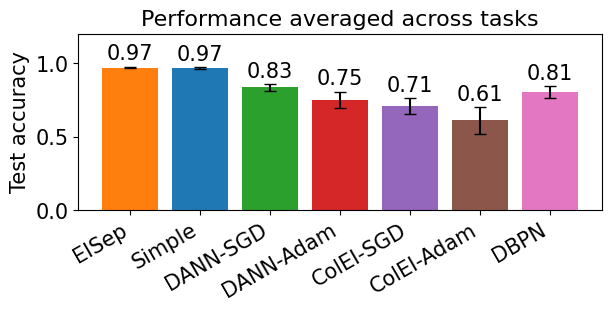

In [14]:
n_seed = 10
# model_names = ['eisep', 'simple',  'entryei', 'fixed_eisep', 'ccstr_simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam']
model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn']
# model_names = ['eisep', 'simple', 'eisep_ei_input', 'eisep_ei_output', 'eisep_ei_both', 'simple_ei_input', 'simple_ei_output', 'simple_ei_both']
# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'EntryEI', 'Fixed-EISep', 'Fixed-EntryEI',  'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam']
legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
# legend_names = ['EISep', 'Simple', 'EISep(I)', 'EISep(O)', 'EISep(B)', 'Simple(I)', 'Simple(O)', 'Simple(B)']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_names = ['eisep']
# legend_names = ['EISep']
test_acc = np.zeros((len(model_names), n_seed, len(env.envs)))
loss_log = np.zeros((len(model_names), n_seed, epochs, 3))
gradient_log = np.zeros((len(model_names), n_seed, epochs, 1))
spectral_radius_log = np.zeros((len(model_names), n_seed, epochs, 1))
rec_balance_log = np.zeros((len(model_names), n_seed, epochs, seq_len))
net_state_dicts = []
colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
# colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00','#009E73']

for i, model_name in enumerate(model_names):
    print(i)
    path = f'./result/multitask/lr1e-2_{model_name}_performance.pkl'
    with open(path, 'rb') as f:
        info = pickle.load(f)
    test_acc[i] = info['performance']
    loss_log[i] = info['loss_log_ei']
    gradient_log[i] = info['gradient_log_ei']
    spectral_radius_log[i] = info['spectral_radius_log_ei']
    rec_balance_log[i] = info['rec_balance_log_ei']
    net_state_dicts.append(info['net_state_dicts'])
# env_names = [e_i.spec.id for e_i in env.envs]
# env_names = [x.split('yang19.')[1].split('-v0')[0] for x in env_names]
env_names = ['Go', 'RT Go', 'Dly Go', 'Anti', 'RT Anti', 'Dly Anti', 'DM 1', 'DM 2', 'Ctx DM 1',
             'Ctx DM 2', 'MultSen DM', 'Dly DM 1', 'Dly DM 2', 'Ctx Dly DM 1', 'Ctx Dly DM 2',
             'MultSen Dly DM', 'DMS', 'DNMS', 'DMC', 'DNMC']


plot_test_performance_all(test_acc, env_names, model_names, colors, legend_names, show_values=True)

In [ ]:
print(test_acc.shape)
acc1 = test_acc[0].reshape(-1)
acc2 = test_acc[2].reshape(-1)
from scipy import stats
t_stat, p_value = stats.ttest_rel(acc1, acc2)
print(f"Paired t-test between {model_names[0]} and {model_names[2]}: t-statistic = {t_stat:.4f}, p-value = {p_value:.4e}")


(7, 10, 20)
Paired t-test between eisep and dann_sgd: t-statistic = -3.2642, p-value = 1.2920e-03


In [ ]:
def test_sparsity_control(net_state_dicts, ob_size, hidden_size, act_size, model_names, env_names):
    test_performance = np.zeros((len(model_names), len(net_state_dicts[0]), len(env_names)))
    for i, model_name in enumerate(model_names):
        print(model_name)
        net = init_model(ob_size, hidden_size, act_size, model_name)
        for j, state_dict in enumerate(net_state_dicts[i]):
            net.load_state_dict(state_dict)
            test_performance[i,j] = test(net, sparsity_control=True)
    return test_performance
test_acc_sc = test_sparsity_control(net_state_dicts, ob_size, hidden_size, act_size, model_names, env_names)


eisep
init, model_name: eisep
EISep Net
Using UnFixed EISep RNN
Evaluating model performance across 100 trials...

Average performance across all environments:
yang19.go-v0: 1.0000
yang19.rtgo-v0: 1.0000
yang19.dlygo-v0: 1.0000
yang19.anti-v0: 1.0000
yang19.rtanti-v0: 1.0000
yang19.dlyanti-v0: 1.0000
yang19.dm1-v0: 0.9300
yang19.dm2-v0: 0.9000
yang19.ctxdm1-v0: 0.8100
yang19.ctxdm2-v0: 0.7800
yang19.multidm-v0: 0.9100
yang19.dlydm1-v0: 0.9000
yang19.dlydm2-v0: 0.9300
yang19.ctxdlydm1-v0: 0.6700
yang19.ctxdlydm2-v0: 0.6600
yang19.multidlydm-v0: 0.7700
yang19.dms-v0: 0.4200
yang19.dnms-v0: 0.5300
yang19.dmc-v0: 1.0000
yang19.dnmc-v0: 1.0000
Evaluating model performance across 100 trials...



KeyboardInterrupt: 

In [ ]:
# np.save('./output/multitask/yang19_sparsity_control_performance.npy', test_acc_sc)
test_acc_sc = np.load('./output/multitask/yang19_sparsity_control_performance.npy')
plot_test_performance_all(test_acc_sc, env_names, model_names, colors, 
                          legend_names, show_values=True, title='Weights-masked')

In [ ]:
error = (test_acc_sc - test_acc)
# print(relative_error.shape)
plot_test_performance_all(error, env_names, model_names, colors, 
                          legend_names, show_values=True, title='Difference of')

In [ ]:


hidden_size = 64
def plot_sparsity(net_state_dicts, ob_size, hidden_size, act_size, model_names, legend_names, colors):
    sparsity_ar = np.zeros((len(model_names), len(net_state_dicts[0])))
    fontsize = 15
    for i, model_name in enumerate(model_names):
        print(model_name)
        net = init_model(ob_size, hidden_size, act_size, model_name)
        for j, state_dict in enumerate(net_state_dicts[i]):
            net.load_state_dict(state_dict)
            weight = net.get_actual_weight().detach().cpu().numpy()
            sparsity = np.mean(np.abs(weight)<0.1*np.std(np.abs(weight)))
            sparsity_ar[i,j] = sparsity
    fig, ax = plt.subplots(figsize=(6,3))
    # ax.set_xmargin(0.03)
    mean_sparsity = np.mean(sparsity_ar, axis=1)
    std_sparsity = np.std(sparsity_ar, axis=1)/np.sqrt(sparsity_ar.shape[1])
    for i in range(len(model_names)):
        bars = ax.bar(i, mean_sparsity[i], yerr=std_sparsity[i], capsize=4, color=colors[i])
        ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=fontsize)
    ax.set_ylim(0,1.1)
    ax.set_xticks(np.arange(len(model_names)))
    ax.set_xticklabels(legend_names, rotation=30, ha='right', fontsize=fontsize-2)
    # ax.set_xticklabels(legend_names, rotation=0,fontsize=fontsize-2)
    # ax.set_ylabel('Sparsity', fontsize=fontsize)
    ax.set_title(f'Sparsity', fontsize=fontsize+3)
    ax.tick_params(labelsize=fontsize)
    plt.tight_layout()
    figname = f'./output/multitask/yang19_model_sparsity.pdf'
    plt.savefig(figname, dpi=400)
    print(figname)
    plt.show()
    plt.close()
    return sparsity_ar

eisep
init, model_name: eisep
EISep Net
Using UnFixed EISep RNN
simple
init, model_name: simple
Using simpleRNN
dann_sgd
init, model_name: dann_sgd
To refactor!, use (SGD, EiRNN_clamp_mixin) instead
EiDense_UpdatePolicy is Deprecated, and doesn't contain
        the correction either please use 
        (BaseUpdatePolicy, cSGD_Mixin, SGD, EiDense_clamp_mixin) 
        for DANN mlps
64 3
dann_adam
init, model_name: dann_adam
64 3
colei_sgd
init, model_name: colei_sgd
colei_adam
init, model_name: colei_adam
dbpn
init, model_name: dbpn
./output/multitask/yang19_model_sparsity.pdf


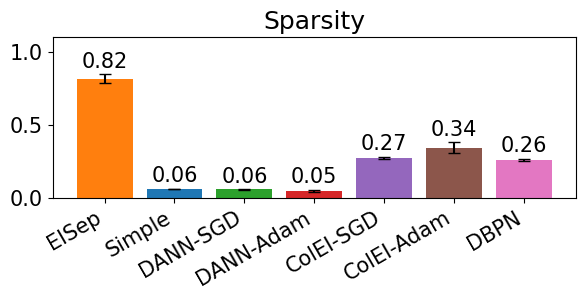

array([[0.86279297, 0.86889648, 0.86694336, 0.86303711, 0.87426758,
        0.83520508, 0.88476562, 0.62768555, 0.61962891, 0.8503418 ],
       [0.05737305, 0.06030273, 0.05371094, 0.06103516, 0.0703125 ,
        0.06323242, 0.06079102, 0.0612793 , 0.05151367, 0.05957031],
       [0.05834961, 0.06201172, 0.05664062, 0.0534668 , 0.05322266,
        0.06030273, 0.06054688, 0.06152344, 0.05688477, 0.05761719],
       [0.09570312, 0.04345703, 0.04711914, 0.05102539, 0.03442383,
        0.08105469, 0.03417969, 0.05297852, 0.01733398, 0.03491211],
       [0.30859375, 0.28564453, 0.28173828, 0.26367188, 0.29125977,
        0.26367188, 0.2722168 , 0.26269531, 0.27124023, 0.24243164],
       [0.41723633, 0.39672852, 0.34375   , 0.37719727, 0.39306641,
        0.34765625, 0.37548828, 0.39086914, 0.3918457 , 0.        ],
       [0.23388672, 0.28222656, 0.26635742, 0.23754883, 0.26318359,
        0.2800293 , 0.27612305, 0.29101562, 0.25292969, 0.23852539]])

In [ ]:
plot_sparsity(net_state_dicts, ob_size, hidden_size, act_size, model_names, legend_names, colors)

In [ ]:
from net.common import init_model
path = f'./result/multitask/lr1e-2_entryei_performance.pkl'
with open(path, 'rb') as f:
    info = pickle.load(f)
# net = SimpleNet(ob_size=ob_size, num_h=64, act_size=act_size).to(device)
# net = EISepNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=False).to(device)
net = init_model(ob_size, hidden_size, act_size, 'entryei').to(device)
net.load_state_dict(info['net_state_dicts'][1])

weight = (net.get_actual_weight()).detach().cpu().numpy()
# mask = net.lstm.mask.detach().cpu().numpy()
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
mask = np.where(eimask[:, 0]>eimask[:, 1], 1, 0)
# exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
exc_ratio = np.where(mask==1, 1, 0).mean()
fig, ax = plt.subplots(1,2,figsize=(12,6))
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
limit = np.max(np.abs(weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
plt.colorbar(im, ax=ax[0])

# im = ax[1].imshow(mask, cmap='RdBu_r', vmin=0, vmax=1)
# plt.colorbar(im, ax=ax[1])
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './result/multitask/lr1e-2_entryei_performance.pkl'

In [ ]:

from tomlkit import ws


def plot_loss_curve_all(n_epoch, colors, model_names, legend_names,
                        loss_log_all, gradient_log_all, spectral_radius_log, rec_balance_log,
                        ):
    # loss_log_all: [n_model, n_seed, n_epoch, 3]
    # gradient_log_all: [n_model, n_seed, n_epoch, 1]
    # spectral_radius_log: [n_model, n_seed, n_epoch, 1]
    # rec_balance_log: [n_model, n_seed, n_epoch, seq_len]
    fig, ax = plt.subplots(1,4, figsize=(22, 5))
    fontsize = 30
    ax = ax.flatten()
    mean_loss = np.nanmean(loss_log_all, axis=1)
    log_mean_loss = np.log(mean_loss + 1e-10)  # Add small constant to avoid log(0)
    std_loss = np.nanstd(loss_log_all, axis=1)
    log_std_loss = np.log(std_loss + 1e-10)  # Add small constant to avoid log(0)

    mean_gradient = np.nanmean(gradient_log_all, axis=1).squeeze()
    log_mean_gradient = np.log(mean_gradient + 1e-10)  # Add small constant to avoid log(0)
    std_gradient = np.nanstd(gradient_log_all, axis=1).squeeze()
    log_std_gradient = np.log(std_gradient + 1e-10)  # Add small constant to avoid log(0)

    mean_spectral_radius = np.nanmean(spectral_radius_log, axis=1).squeeze()
    std_spectral_radius = np.nanstd(spectral_radius_log, axis=1).squeeze()

    # mean_rec_balance = np.nanmean(rec_balance_log, axis=(1,-1))
    # std_rec_balance = np.nanstd(rec_balance_log, axis=(1,-1))
    loss_idx = 1
    for i, model_name in enumerate(legend_names):
        if True:  # DANN has no loss log
            ax[0].plot(mean_loss[i, :, loss_idx], label=model_name, color=colors[i], alpha=0.9)
            ax[0].fill_between(np.arange(n_epoch), mean_loss[i, :, loss_idx] - std_loss[i, :, loss_idx], mean_loss[i, :, loss_idx] + std_loss[i, :, loss_idx], alpha=0.1, color=colors[i])
            ax[1].plot(mean_gradient[i], label=model_name, color=colors[i], alpha=0.9)
            ax[1].fill_between(np.arange(n_epoch), mean_gradient[i] - std_gradient[i], mean_gradient[i] + std_gradient[i], alpha=0.1, color=colors[i])
            ax[2].plot(mean_spectral_radius[i], label=model_name, color=colors[i], alpha=0.9)
            ax[2].fill_between(np.arange(n_epoch), mean_spectral_radius[i] - std_spectral_radius[i], mean_spectral_radius[i] + std_spectral_radius[i], alpha=0.1, color=colors[i])
            ax[3].plot(np.zeros((1,)), label=model_name, color=colors[i], alpha=1, linewidth=10)
            # ax[3].fill_between(np.arange(n_epoch), mean_rec_balance[i] - std_rec_balance[i], mean_rec_balance[i] + std_rec_balance[i], alpha=0.1, color=colors[i])

    # Plot for the first model at the top
    ax[0].plot(mean_loss[0, :, loss_idx], label=model_name, color=colors[0], alpha=0.9)
    ax[0].fill_between(np.arange(n_epoch), mean_loss[0, :, loss_idx] - std_loss[0, :, loss_idx], mean_loss[0, :, loss_idx] + std_loss[0, :, loss_idx], alpha=0.1, color=colors[0])
    ax[1].plot(mean_gradient[0], label=model_name, color=colors[0], alpha=0.9)
    ax[1].fill_between(np.arange(n_epoch), mean_gradient[0] - std_gradient[0], mean_gradient[0] + std_gradient[0], alpha=0.1, color=colors[0])
    ax[2].plot(mean_spectral_radius[0], label=model_name, color=colors[0], alpha=0.9)
    ax[2].fill_between(np.arange(n_epoch), mean_spectral_radius[0] - std_spectral_radius[0], mean_spectral_radius[0] + std_spectral_radius[0], alpha=0.1, color=colors[0])


    # ax[0].set_title('Loss', fontsize=fontsize)
    ax[0].set_ylim([1e-3,1e5])
    ax[0].set_yscale('log')
    # ax[1].set_title('Gradient norm', fontsize=fontsize)
    ax[1].set_ylim([1e-3,1e5])
    ax[1].set_yscale('log')
    # ax[2].set_title('Spectral radius', fontsize=fontsize)
    ax[2].set_ylim([-1,15])
    ax[3].legend(fontsize=fontsize-5, loc='center left', framealpha=1, shadow=True, markerscale=1)
    ax[3].axis('off')

    # ax[3].set_title('Recurrent balance', fontsize=fontsize)

    for a in ax:
        a.tick_params(labelsize=fontsize-10)
        a.set_xlabel('Epoch', fontsize=fontsize)

    # plt.subplots_adjust(wspace=0.4)
    plt.tight_layout()
    figname = './output/multitask/yang19_loss_curve.png'
    plt.savefig(figname, dpi=400)
    print(figname)
    plt.show()

./output/multitask/yang19_loss_curve.png


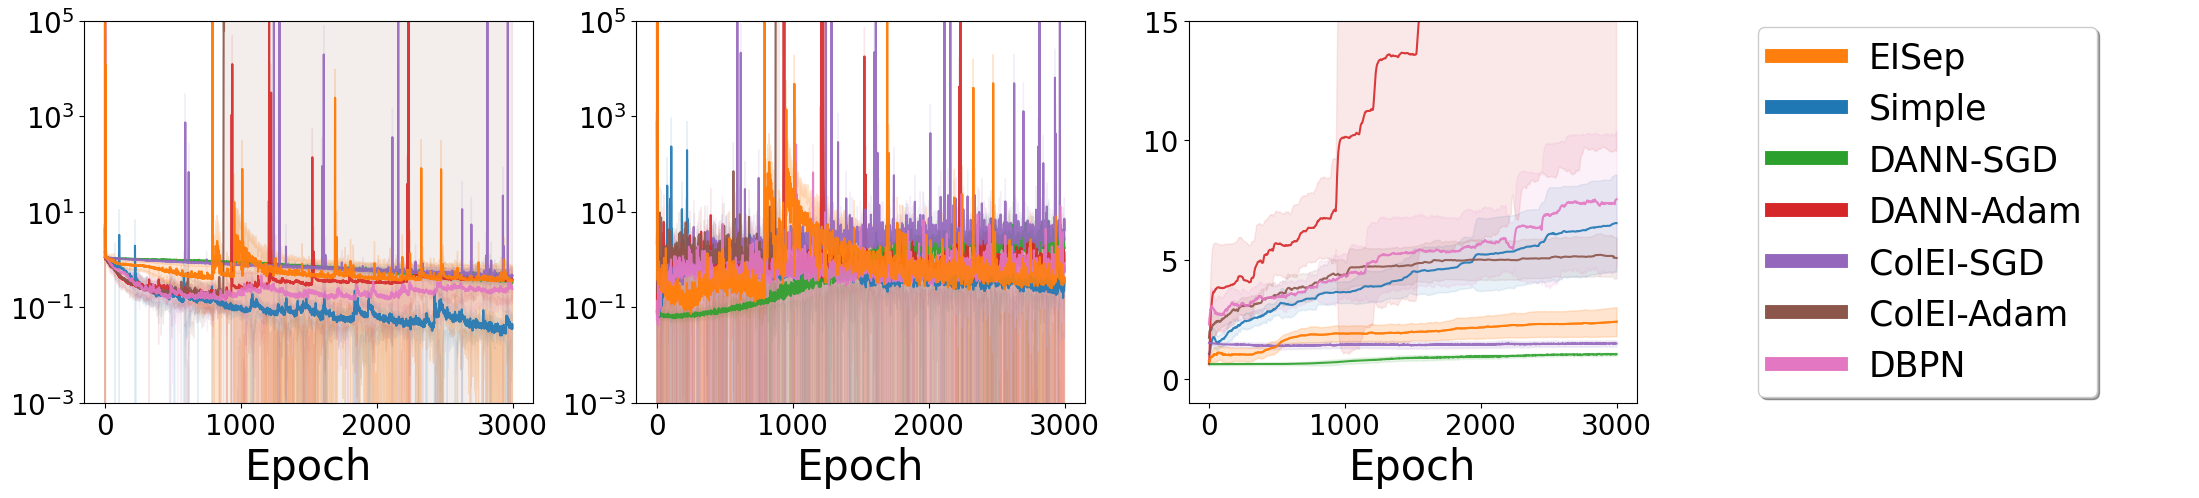

In [ ]:
plot_loss_curve_all(epochs, colors, model_names, legend_names, loss_log, gradient_log, spectral_radius_log, rec_balance_log)
# print(loss_log)

In [ ]:
# from cut import signed_spectral_W, lift_spectral_W
from new_cut import lift_spectral_W, signed_spectral_W
def cal_modularity(net_state_dicts, ob_size, hidden_size, act_size, model_names, colors):
    # net_state_dicts: list of list of state_dict
    # model_names: list of model names
    # Returns: Q_all, Frustr_all, Ncut_all: [n_model, n_seed, n_k]
    metric_name = ['Q', 'Frustration', 'Ncut']
    k_min = 2
    k_max = 10
    Q_all = np.zeros((len(model_names), n_seed, k_max - k_min + 1))
    Frustr_all = np.ones((len(model_names), n_seed, k_max - k_min + 1))
    Ncut_all = np.ones((len(model_names), n_seed, k_max - k_min + 1))
    for i, model_name in enumerate(model_names):
        print(model_name)
        net = init_model(ob_size, hidden_size, act_size, model_name)
        for j, state_dict in enumerate(net_state_dicts[i]):
            net.load_state_dict(state_dict)
            weight = net.get_actual_weight().detach().cpu().numpy()
            print(f'Seed {j}, weight mean: {weight.mean():.4f}, std: {weight.std():.4f}')
            if np.isnan(weight).any():
                print('Weight contains NaN, skip')
                continue
            # transpose
            weight_row = weight.T
            # df, _ = signed_spectral_W(weight_row, k_min, k_max, restarts=5, seed=0)
            df, _ = lift_spectral_W(weight_row, k_min, k_max, restarts=5, seed=0)
            Q_all[i,j] = df['Q'].values
            Frustr_all[i,j] = df['Frustr'].values
            Ncut_all[i,j] = df['Ncut'].values

    return Q_all, Frustr_all, Ncut_all


In [ ]:
Q_all, Frustr_all, Ncut_all = cal_modularity(net_state_dicts, ob_size, hidden_size, act_size, model_names, colors)

eisep
init, model_name: eisep
EISep Net
Using UnFixed EISep RNN
Seed 0, weight mean: -0.0202, std: 0.2082
Seed 1, weight mean: -0.0246, std: 0.2250
Seed 2, weight mean: -0.0332, std: 0.2409
Seed 3, weight mean: -0.0280, std: 0.2427
Seed 4, weight mean: -0.0278, std: 0.2254
Seed 5, weight mean: -0.0277, std: 0.2263
Seed 6, weight mean: -0.0364, std: 0.2563
Seed 7, weight mean: -0.0260, std: 0.0878
Seed 8, weight mean: -0.0194, std: 0.0909
Seed 9, weight mean: -0.0284, std: 0.1729
simple
init, model_name: simple
Using simpleRNN
Seed 0, weight mean: -0.0692, std: 0.2514
Seed 1, weight mean: -0.1418, std: 0.3581
Seed 2, weight mean: -0.0827, std: 0.2415
Seed 3, weight mean: -0.0987, std: 0.2611
Seed 4, weight mean: -0.1228, std: 0.3245
Seed 5, weight mean: -0.1101, std: 0.2999
Seed 6, weight mean: -0.1634, std: 0.3312
Seed 7, weight mean: -0.1523, std: 0.3457
Seed 8, weight mean: -0.1204, std: 0.3130
Seed 9, weight mean: -0.1219, std: 0.3095
dann_sgd
init, model_name: dann_sgd
To refactor!

KeyboardInterrupt: 

In [ ]:
# modularity_metrics = {
#     'Q': Q_all, 'Frustration': Frustr_all, 'Ncut': Ncut_all
# }
# pickle.dump(modularity_metrics, open('./output/multitask/modularity_metrics_directed_spectral.pkl','wb'))

./output/multitask/yang19_modularity.png


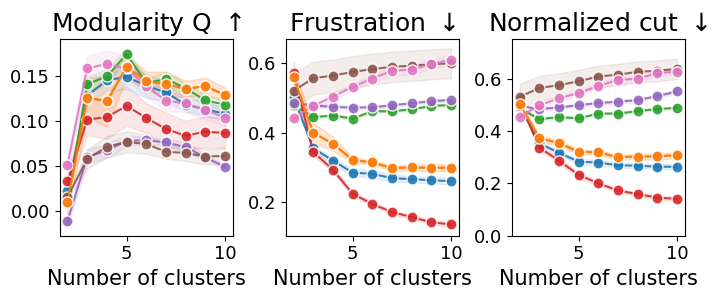

In [ ]:
metric_name = ['Q', 'Frustration', 'Ncut']
# metrics = pickle.load(open('./output/multitask/modularity_metrics.pkl', 'rb'))
# metric_name = metrics.keys()
# Q_all, Frustr_all, Ncut_all = list(metrics.values())
k_min = 2
k_max = 10
fig, ax = plt.subplots(1,1, figsize=(3,2.5))
fontsize = 15
# ax = ax.flatten()
ax = [ax]
for i, metric in enumerate([Q_all, Frustr_all, Ncut_all]):
    if i>0:
        break
    mean_metric = np.mean(metric, axis=1)
    std_metric = np.std(metric, axis=1)/np.sqrt(metric.shape[1])
    for j in reversed(range(len(model_names))):
        ax[i].plot(np.arange(k_min, k_max+1), mean_metric[j], label=model_names[j], color=colors[j], alpha=0.9, marker='o',
                   markeredgecolor='white', markeredgewidth=1, markersize=8)
        ax[i].fill_between(np.arange(k_min, k_max+1), mean_metric[j]-std_metric[j], mean_metric[j]+std_metric[j], alpha=0.1, color=colors[j])
        # ax[i].errorbar(np.arange(k_min, k_max+1), mean_metric[j], yerr=std_metric[j], color=colors[j], alpha=0.9)
    ### Replot the first model at the top
    # ax[i].plot(np.arange(k_min, k_max+1), mean_metric[0], label=model_names[0], color=colors[0], alpha=0.9, marker='o',
    #            markeredgecolor='white', markeredgewidth=1, markersize=8)
    # ax[i].fill_between(np.arange(k_min, k_max+1), mean_metric[0]-std_metric[0], mean_metric[0]+std_metric[0], alpha=0.1, color=colors[0])

    if i == 0:
        ax[i].set_title(r'Lifted Spectral', fontsize=fontsize+3)
        # ax[i].set_ylim([0, 0.6])
    elif i == 1:
        ax[i].set_title(r'Frustration $\downarrow$', fontsize=fontsize+3)
        # ax[i].set_ylim([0, 0.5])
    elif i == 2:
        ax[i].set_title(r'Normalized cut $\downarrow$', fontsize=fontsize+3)
        # ax[i].set_ylim([0, 0.75])
    ax[i].set_xlabel('Number of clusters', fontsize=fontsize)
    ax[i].set_xticks(np.arange(k_min, k_max+1))
    # ax[i].set_ylabel(metric_name[i], fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize-2)
    # ax[i].legend(fontsize=fontsize, loc='lower left')
plt.tight_layout()
figname = './output/multitask/yang19_modularity_lifted_spectral.png'
plt.savefig(figname, dpi=400)
print(figname)
plt.show()
plt.close()

In [ ]:
from matplotlib.pyplot import savefig


fig, ax = plt.subplots(1,1, figsize=(8,1))
fontsize = 15
for i, model_name in enumerate(legend_names):
    ax.plot(np.zeros((1,)), label=model_name, color=colors[i], alpha=1, linewidth=10)
ax.legend(fontsize=fontsize, loc='center left', framealpha=1, shadow=True, markerscale=1, ncols=4)
ax.axis('off')
plt.tight_layout()
figname = './output/multitask/yang19_modularity_legend.png'
savefig(figname, dpi=400)
print(figname)

(10, 3000)


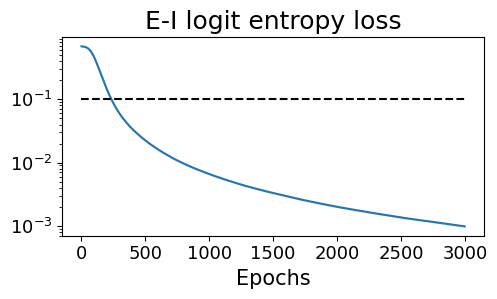

./output/multitask/yang19_ei_entropy_loss.pdf


In [ ]:
path = f'./result/multitask/lr1e-2_eisep_performance.pkl'
with open(path, 'rb') as f:
    info = pickle.load(f)
ei_entropy_loss = info['loss_log_ei'][...,2]
print(ei_entropy_loss.shape)
mean_ei_entropy_loss = ei_entropy_loss.mean(0)
ste_ei_entropy_loss = ei_entropy_loss.std(0)/np.sqrt(ei_entropy_loss.shape[0])
fig, ax = plt.subplots(1,1,figsize=(5,3))
fontsize = 15
ax.plot(mean_ei_entropy_loss)
ax.fill_between(np.arange(mean_ei_entropy_loss.shape[0]), mean_ei_entropy_loss-ste_ei_entropy_loss,
                mean_ei_entropy_loss+ste_ei_entropy_loss, alpha=0.2, color='C1')
ax.set_xlabel('Epochs', fontsize=fontsize)
ax.set_xticks(np.arange(0, epochs+1, 500), labels=np.arange(0, epochs+1, 500))
ax.hlines(0.1, 0, epochs, colors='k', linestyles='dashed')
# ax.set_ylabel('EI Logit entropy loss', fontsize=fontsize)
ax.set_yscale('log')
ax.set_title('E-I logit entropy loss', fontsize=fontsize+3)
ax.tick_params(labelsize=fontsize-2)
plt.tight_layout()
plt.savefig('./output/multitask/yang19_ei_entropy_loss.pdf', dpi=400)
plt.show()
print('./output/multitask/yang19_ei_entropy_loss.pdf')

In [ ]:
path = f'./result/multitask/lr1e-2_eisep_test.pkl'
with open(path, 'rb') as f:
    info = pickle.load(f)
eimask_logit = info['ei_logit_log_ei']
n_epoch = 3000
n_lyapunov = eimask_logit.shape[1]
lyapunov_every = n_epoch // n_lyapunov
fig, ax = plt.subplots(4, n_lyapunov//4, figsize=(15, 8))
fontsize = 15
ax = ax.flatten()
labels = ['Exc logit', 'Inh logit']
colors = ['tomato', 'turquoise']
for i in range(n_lyapunov):
    for j in range(eimask_logit.shape[-1]):
        ax[i].plot(eimask_logit[0,i,:,j], label=labels[j], color=colors[j])
    ax[i].set_title(f'Epoch {i+1}*{lyapunov_every}', fontsize=fontsize)
    if i >= 15:
        ax[i].set_xlabel('Hidden Units', fontsize=fontsize)
    if i % 5 == 0:
        ax[i].set_ylabel('EI logit', fontsize=fontsize)
    # ax[i].tick_params(labelsize=10)
    # ax[i].legend(fontsize=fontsize)
plt.tight_layout()
plt.savefig('./output/multitask/yang19_eimask_logit.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(4,3))
ax.plot(0,0,label='First logit', color='tomato')
ax.plot(0,0,label='Second logit', color='turquoise')
ax.legend(fontsize=fontsize, loc='center left', framealpha=1, shadow=True, markerscale=1)
ax.axis('off')
plt.savefig('./output/multitask/eisep_logit_legend.png', dpi=400)
plt.show()

In [ ]:
# from pdm_model import Net, SimpleNet
# device = 'cuda:0'
# batch_size = 64
# hidden_size = 64
# net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
# simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)
# net_path = './model/multitask/yang19_ei_softplus.pth'
# simple_net_path = './model/multitask/yang19_simple_tanh.pth'
# net.load_state_dict(torch.load(net_path))
# simple_net.load_state_dict(torch.load(simple_net_path))

In [ ]:
n_test = 10
def plot_activity(hidden_size, net, color):
    net.eval()
    fig, ax = plt.subplots((hidden_size-1)//8+1, 8, figsize=(32, (hidden_size//8+1)*3))
    ax = ax.flatten()
    inputs, targets = dataset()
    inputs = torch.from_numpy(inputs).float().to(device)
    targets = torch.from_numpy(targets).long().to(device)

    outputs, eimask_logit, hidden = net(inputs)
    # print('hidden', hidden.shape)
    h_all = hidden[0].detach().cpu().numpy()
    h_all_mean = h_all.mean(1)
    h_all_std = h_all.std(1)
    for j in range(hidden_size):
        ax[j].plot(h_all_mean[:,j], color=color)
        ax[j].fill_between(np.arange(seq_len), h_all_mean[:,j]-h_all_std[:,j], h_all_mean[:,j]+h_all_std[:,j],
                           alpha=0.2, color=color)
    normalized_variance = (h_all_std/(h_all.max((0,1))-h_all.min((0,1)))).mean()
    # normalized_variance = h_all_std.mean()

    plt.suptitle(f'Normalized variance: {normalized_variance:.4f}', fontsize=30)
    plt.tight_layout()
    plt.show()
    plt.close()


In [ ]:
plot_activity(hidden_size, net, 'C0')

In [ ]:
plot_activity(hidden_size, simple_net, 'C1')